# Exercise 1: Entanglement Circuit

In this exercise, you will learn how to make a quantum circuit that enables two-qubit entanglement. 

After practicing how to use a simulator, you will be able to send the circuit to an actual quantum hardware (IBM) and get the results. 
To use an IBM quantum machine, you need an IBM Cloud account that is set up for `Quantum Compute` service. See the preparation code notebook for how-to. 

## What is entanglement?

Entanglement gives us an ability to infer about a qubit's state by looking at its entangled counterpart. 
For example, if two qubit (A and B) are entangled in a way that both are measured to be the same state (i.e., Bell state), then whenever we measure A to be $\ket{0}$, the measurement outcome of B must be also $\ket{0}$.

In this exercise, we are going to create a quantum circuit that creates a Bell state
where we have the equal probability to measure $\ket{00}$ and $\ket{11}$ (i.e., 50:50).
To do so, we will superpose a qubit and then associate this with another qubit. 

In [180]:
import qiskit
import matplotlib
import altair as alt
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke

## Step 1. Initiate a quantum circuit.
The below code creates a logical circuit object (with no gates added) with `2` qubits and `2` classical bits (where qubit measurments are stored).
The first argument of the `QuantumCircuit` class is the number of qubits, and the last is the number of classical bits.
Many of Qiskit-like low-level toolkits do not support dynamic changes to the number of bits. 

In [6]:
qc = qiskit.QuantumCircuit(2,2)

## Step 2-1. Our first gate: Hadamard (H) gate

The below line adds a Hadamard (or H) gate to the first qubit (`q[0]`). 
An H gate enables equal superposition, where the theoretical probability of measuring the qubit to be $\ket{0}$ is 0.5.

In [7]:
qc.h(0)

## Step 2-2. Control-Not (CX, C-Not) gate

We are now adding a Control-Not (or CX, C-Not) gate. 
This gate applies to two qubits: one control and one target.
Like any controlled gates, if a control qubit's state is $\ket{0}$, 
then the specified operation is appled to the target gate. 
For example, a CX gate operates the X gate (or Not gate) to its target qubit
when its control qubit's state is $\ket{0}$.
CX gate is one of the fundamental multi-qubit gates along with SWAP, CCX, and CZ gates. 
Note that, there are controlled gates with multiple controls and multiple targets. 

In the code, the first argument is the control qubit, and the last is the target.
A common mistake is to flip the order.

In [8]:
qc.cx(0, 1)
# WRONG (in this case): qc.cx(1, 0)

## Step 2-3. Add measurments

To get the results, we need to add measurements. 
Not every qubit needs to be measured. 
Some qubits are used to assist operations (i.e., ancilla qubits) and they do not need to be measured. 
Typically, measurements for the results happen at the end of the circuit. 
Theoretically, when measurement happens should not impact the quality of the outcome,
but practically, it matters a lot because qubits lose its coherence pretty quickly.
Mnay modern compilers measures a qubit as soon as all the gates for it is done. 

There are two ways to measure qubits. 
First, specify which qubit is measured to which classical bits (we are doing this). 
This is safe and makes it a bit easier to interpret the outcomes, but it is difficult to specify them.
Second, use `measure_all` or just specify which qubits to measure.
This might make it obscure to see which qubit's data is stored where. 
But, you can provide the original circuit design when re-interpreting the measurement outcomes. 

In [9]:
qc.measure([0, 1], [0, 1])
# qc.measure_all()

# Step 3. Let's check our circuit

Qiskit supports three methods for drawing circuits: png (`mpl`), text (`text`), and latex (`latex`, requires `pdftocairo` pacakge).

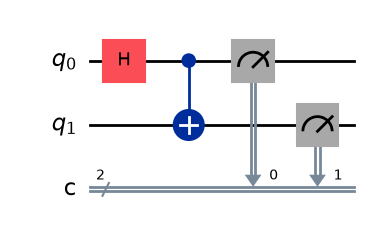

In [14]:
qc.draw("mpl")

# Step 4. Choose a backend (QPU)

What we have created so far is a logical circuit, which expresses operations in a theoretical way.
To run a circuit, we need to re-express this in a phyiscal way using physical gates supported by individual quantum processing units (QPUs).
We need to choose a backend before running a circuit because each QPU has a different set of supported physical gates.
Plus, while converting a logical circuit into a physical circuit (called transpilation, compilation, or circuit optimization),
QPU's fidelity information is combined as well, which is another reason we need to choose a QPU first.

The code right below here is a utility to save an IBM Cloud API key.

In [16]:
from qiskit_ibm_runtime import QiskitRuntimeService
import os 

def get_api_key(env_var_name=None, ext_file_path=None):
    my_token = None
    if env_var_name is not None:
        my_token = os.environ.get(env_var_name)
        QiskitRuntimeService.save_account(token=my_token, overwrite=True)
    elif ext_file_path is not None:
        with open(ext_file_path, "r") as f:
            my_token = f.read()
            QiskitRuntimeService.save_account(token=my_token, overwrite=True)
    else:
        print("You saved it, right?")

**If you followed the tutorial, please use `env_var_name`**

In [83]:
# # if you saved it as am environment variable, then provide the name.
# get_api_key(env_var_name="<VAR_NAME>")
# # if you saved it in a text file, then provide the path.
# get_api_key(ext_file_path="<FILE_PATH>")

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/443edfe2002d4ce9aa5af6108d861bc8:4d277211-7b98-4a75-ba44-880c9dde4d9f::"
)

The below code gets the least buy QPU at the moment.
(Ignore warnings)

In [23]:
# get instance information
backend_real = service.least_busy(simulator=False, operational=True)
backend_real

qiskit_runtime_service.backends:WARNING:2026-09-29 11:48:52,434: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-09-29 11:48:56,126: Using instance: open-instance, plan: open


<IBMBackend('ibm_marrakesh')>

## Step 5. Transpile a circuit

Now, we are going to transpile (= compile an object at the same level of abstraction) a circuit.
Via Qiskit, we first need to set up a pass manager (an object that runs transpilation steps).
Optimization level (from 0 to 3) refers to how much optimization happens (i.e., optimized for qubit/gate fidelities and so on).

In [31]:
pass_manager = generate_preset_pass_manager(
    optimization_level=3, backend=backend_real
)

# # For those without an IBM Cloud account set up, use the below code.
# backend_fake = FakeSherbrooke()
# pass_manager = generate_preset_pass_manager(
#     optimization_level=3, backend=backend_fake
# )

Next, we run the pass manager and draw the circuit.
In the `draw` method below, we set `idle_wires` to `False` because now it is a physical circuit, so it includes all the qubits that are not used for our operation that could cause visual clutter.

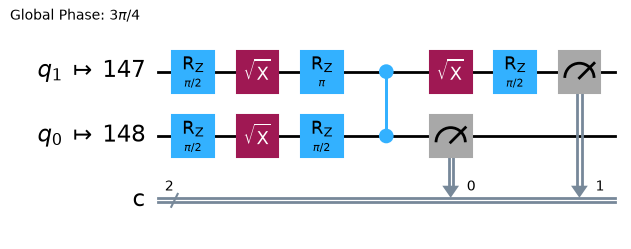

In [32]:
qc_transpiled = pass_manager.run(qc)
qc_transpiled.draw("mpl", idle_wires=False)

# Step 6. Run it on a simulator

Before running it on a QPU, let's do a sanity check with a simulator.
Note that we can do this because our circuit is really small. 
For those with much more gates and qubits, simulator might cost a lot (your laptop won't be able to process it).

For large-scale simulators, take a look at [AWS Braket](https://aws.amazon.com/braket/pricing/#Simulators). 
It is possible to use AWS Braket services with quantum circuits coded using Qiskit with [additional settings](https://aws.amazon.com/blogs/quantum-computing/introducing-the-qiskit-provider-for-amazon-braket/)

The below circuit creates a simulator using the backend we specified.

In [33]:
backend = backend_real
# # If you are using a fake backend, then run the below code.
# backend = backend_fake

from qiskit_aer import AerSimulator
backend_sim = AerSimulator.from_backend(backend)

## Step 6-1. Shots

When running a simulator or real QPU, we need to specify the number of `shots`. 
Default is about 4,000 for Qiskit + IBM Quantum.
The number of shots depend on the problem and its size. 
In some cases like Grover's search, there is theoretical optimal number of measurements.
It is not always determined for every problem.

In [36]:
job_sim = backend_sim.run(qc_transpiled, shots=1024)
result_sim = job_sim.result()

In [37]:
counts_sim = result_sim.get_counts()
counts_sim

{'01': 3, '10': 1, '11': 492, '00': 528}

## Step 6-2. Let's visualize

You can visualize a circuit using the default utility funciton of Qiskit or via custom toolkits like Altair.
We are going to do both.

### Via Qiskit utility

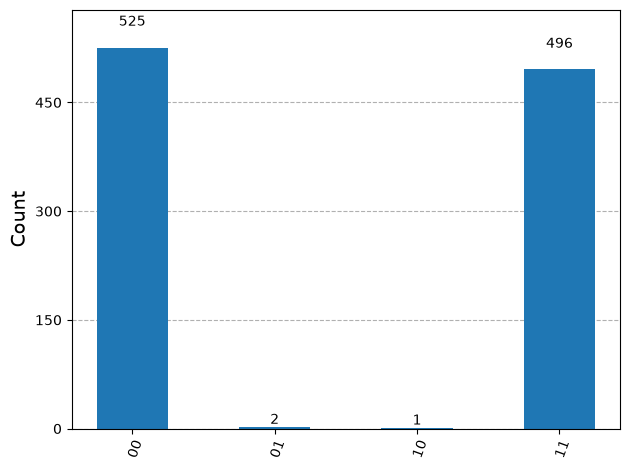

In [48]:
from qiskit.visualization import plot_histogram
plot_histogram(result.get_counts())

As you can see, we almost got the same counts for the $\ket{00}$ and $\ket{11}$.

### Via Altair

Just in case you'd want to make some useful utilities out of this (e.g., interactivity for large-scale measurement outcomes)
If you installed Altair, then `pandas` is also installed (usually).

In [147]:
import pandas as pd

def counts_to_df(count_dict: dict, machine: str):
    states = []
    counts = []
    machines = []
    for state in count_dict.keys():
        states.append(state)
        counts.append(count_dict[state])
        machines.append(machine)
    return pd.DataFrame({"states": states, "counts": counts, "machines": machines})

In [150]:
counts_sim_df = counts_to_df(counts_sim, "simulator")
counts_sim_df

,states,counts,machines
0,01,3,simulator
1,10,1,simulator
2,11,492,simulator
3,00,528,simulator


In [177]:
def make_chart(data: pd.DataFrame, title: str):
    chart = alt.Chart(data, title=title).mark_tick(thickness=5).encode(
        x = alt.X(field="states", type="ordinal", title="States"),
        y = alt.Y(field="counts", type="quantitative", title="Counts"),
        color = alt.Color(field="machines", type="nominal", title="Machine type", scale=alt.Scale(domain=["simulator", "real QPU"])),
        tooltip = [alt.Tooltip(field="states", title="State"), alt.Tooltip(field="counts", title="Count"), alt.Tooltip(field="machines", title="Machine")]
    )
    return chart
chart_sim = make_chart(counts_sim_df, "Simulated outcome")
chart_sim

alt.Chart(...)

# Step 7. To a real machine

Now we are going to send our circuit to a real-world QPU.
To do so, we need to set Primitive. 

In Qiskit, a Primitive can be either `Sampler` or `Estimator`.
A sampler is for getting measurment outcomes, and an estimator is for estimating parameters through adiabatic procedures.
We are going to use a sampler because we want to get measurement outcomes.

In [93]:
from qiskit_ibm_runtime.executor_sampler import Sampler
sampler = Sampler(mode=backend)

The below code runs the circuit on an actual QPU. 

In [94]:
# job_qpu = sampler.run([qc_transpiled], shots=1024)

qiskit_runtime_service.backends:WARNING:2026-09-29 16:12:50,791: Using instance: open-instance, plan: open


### Step 7-1. Check the status

To check the status, use the below code.

In case you run into an error: [Error codes](69c05765-a7dd-4426-bdc9-884fbc7f3a79)

In [125]:
job_id_qpu = job_qpu.job_id()
job_status_qpu = job_qpu.status()
print("Job ID: ", job_id_qpu)
print("Job Status: ", job_status_qpu)

Job ID:  datm9tbg95ks73eh6hug
Job Status:  DONE


## Step 8. Retrieve outcomes (when complete)

You can reaccess your job by its ID. You can also find it from IBM Quantum Platform.

In [126]:
job_qpu = service.job(job_id_qpu)
result_qpu = job_qpu.result()

Depending on how the measurement is set, there are different ways to retrieve the measurement counts.

In [133]:
measure_all = 'meas' in dir(result_qpu[0].data)
measure_c = 'c' in dir(result_qpu[0].data)

In [157]:
counts_qpu = None
if measure_all:
    # When using measure all
    counts_qpu = result_qpu[0].data.meas.get_counts()
elif measure_c:
    # in our method
    counts_qpu = result_qpu[0].data.c.get_counts()
counts_qpu

{'11': 473, '00': 532, '10': 7, '01': 12}

### Step 8-1. Visualize

In [178]:
# if counts_qpu is not None:
counts_qpu_df = counts_to_df(counts_qpu, "real QPU")
chart_qpu = make_chart(counts_qpu_df, "Real QPU outcome")
chart_qpu

alt.Chart(...)

## Let's compare the simulated and real outcomes

Below, you might see that the real QPU outcomes are more noisy (higher counts in theoretically not plausible outcome).

In [179]:
chart_sim + chart_qpu

alt.LayerChart(...)